In [1]:
rm(list = ls())
options(stringsAsFactors = FALSE)
getwd()

[1] "/Users/luye/Library/Mobile Documents/com~apple~CloudDocs/Projects/Ongoing/202504ZL"

In [3]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(stringr)
library(tidyverse)
library(limma)
library(tibble)
library(caret)
library(glmnet)
library(pROC)
library(mclust) # or library(fossil)

In [5]:
dir <- "1-Clustering"
data_dir <- file.path(dir, "data")

In [6]:
load(file = paste0(data_dir, "/combined_expr_after_correction.rds"))
dim(corrected_expr_limma)
head(corrected_expr_limma)

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,10.82928,10.890999,11.94522,12.778273,10.995143,11.226208,10.035329,10.398659,11.30408,12.16933,...,10.99660,11.026177,11.094798,12.008558,11.481356,12.627119,11.769922,11.4156781,11.201563,9.495304
ALB,12.05004,13.178437,10.79637,5.770313,7.063872,4.553839,12.638745,12.447035,10.08065,10.02450,...,11.00465,12.196094,10.683190,12.497491,2.410946,8.453237,7.411365,0.4926482,12.583942,7.533481
FTL,10.66605,12.897749,11.72236,11.072817,12.143254,12.137395,13.854919,12.317509,11.09063,11.08043,...,11.76724,9.781075,10.558542,10.432385,12.301201,12.339945,13.363718,11.6431148,10.730668,11.445058
S100A6,10.31944,5.593509,11.54254,10.995845,11.064880,10.134493,7.784021,10.904630,10.58029,10.69710,...,10.62347,10.704640,8.700956,7.914385,12.343699,11.888619,10.589558,8.2747927,8.948155,8.407319
RPS18,10.09080,10.167330,10.44833,10.278913,9.563777,9.050844,9.202332,9.774162,11.49839,10.09671,...,10.64097,11.134008,9.614914,10.565745,9.542747,9.639386,9.873656,11.1388385,10.614570,9.653813
TMSB4X,10.61613,10.408689,11.31893,11.724414,11.308622,11.295856,10.777988,11.413705,10.88848,11.85332,...,10.43501,10.587907,10.379686,11.303271,11.737150,11.998210,10.570807,12.4690672,10.863712,9.242494


In [7]:
sample_cluster <- readxl::read_excel(paste0(data_dir, "/sample_info_with_clusters.xlsx"))
dim(sample_cluster)
head(sample_cluster)

[1] 586  37

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,...,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,...,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


In [8]:
table(sample_cluster$'iCCA classification')


large duct type small duct type             w/o 
             29              86             471 

In [9]:
# 仅保留有大小导管标签的样本
idx <- which(sample_cluster$`iCCA classification` %in% c("large duct type", "small duct type"))
samples_labeled <- sample_cluster$Sample[idx]
labels <- sample_cluster$`iCCA classification`[idx]
labels <- factor(labels, levels = c("large duct type", "small duct type"))

# 提取对应表达矩阵
expr_labeled <- corrected_expr_limma[, samples_labeled]

In [10]:
table(labels)

labels
large duct type small duct type 
             29              86 

In [11]:
dim(expr_labeled)
head(expr_labeled)

[1] 10531   115

,CCA#101,CCA#103,CCA#105,CCA#110,CCA#112,CCA#115,CCA#116,CCA#119,CCA#120,CCA#121,...,GSM6654040,GSM6654041,GSM6654042,GSM6654043,GSM6654044,GSM6654045,GSM6654046,GSM6654047,GSM6654048,GSM6654049
TMSB10,12.19251,11.477953,11.600475,11.072019,11.699631,12.20387,10.474883,11.395230,10.976686,10.530991,...,11.464082,11.343400,8.710696,10.793117,9.068309,12.3890651,13.136158,11.929438,13.342997,13.557121
ALB,11.44534,10.817940,11.510378,11.681501,11.258280,11.42383,4.395258,10.285498,8.384182,10.841793,...,10.211622,16.148670,17.169020,10.656663,17.167334,0.7836805,3.473427,6.031228,1.100753,4.036005
FTL,10.26602,11.723151,11.789555,12.682074,12.280300,11.41269,13.667428,10.987194,10.762722,10.410607,...,13.214686,13.491675,12.949565,12.513667,11.963543,10.7424037,9.572040,10.849361,9.745322,8.868441
S100A6,10.33172,10.765493,9.253747,11.563948,10.491063,10.86341,11.185596,11.870757,10.180262,8.744576,...,8.357463,7.207138,5.639361,7.123203,7.323112,14.0316880,14.146727,14.115920,14.494861,14.840506
RPS18,11.44145,9.283102,9.741696,9.471471,10.640080,10.73380,10.005437,9.146349,11.058341,10.332445,...,9.958281,8.231506,9.134372,10.754728,8.651455,9.3572489,10.221102,10.738071,10.800371,10.235943
TMSB4X,10.31151,10.905108,10.808425,10.986224,9.685647,11.96528,11.743643,11.001970,9.782205,10.065866,...,10.392315,11.621144,9.722259,11.548502,9.839122,10.9282986,11.233866,11.293245,11.292414,11.740538


## DEG

In [12]:
# 创建输出目录
output_dir <- "2-Classfiler"
dir.create(output_dir, showWarnings = FALSE, recursive = TRUE)
fig_dir <- file.path(output_dir, "figures")
dir.create(fig_dir, showWarnings = FALSE)
data_dir <- file.path(output_dir, "data")
dir.create(data_dir, showWarnings = FALSE)

In [13]:
library(limma)
design <- model.matrix(~ labels)
fit <- lmFit(expr_labeled, design)
fit <- eBayes(fit)
deg <- topTable(fit, coef=2, number=Inf, adjust.method="BH")
write.csv(deg, file=paste0(data_dir,"/deg_LS.csv"))

In [14]:
# 如果还没有 'gene' 列，可以加上
deg$gene <- rownames(deg)
# 设置阈值
logfc_cutoff <- 1
padj_cutoff <- 0.05

deg$change <- "NotSig"
deg$change[deg$logFC > logfc_cutoff & deg$adj.P.Val < padj_cutoff] <- "Up"
deg$change[deg$logFC < -logfc_cutoff & deg$adj.P.Val < padj_cutoff] <- "Down"
table(deg$change)



  Down NotSig     Up 
   122  10198    211 

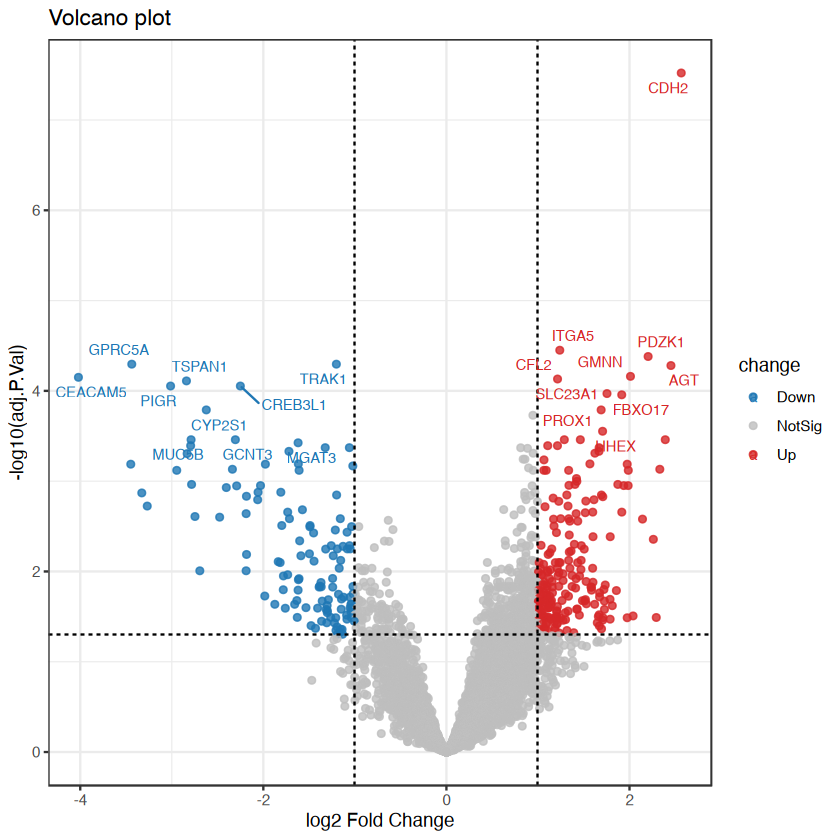

In [15]:
# 标记top10上调和下调
library(ggrepel)
top_up <- deg[deg$change=="Up", ][order(deg[deg$change=="Up", "adj.P.Val"]), ][1:10, ]
top_down <- deg[deg$change=="Down", ][order(deg[deg$change=="Down", "adj.P.Val"]), ][1:10, ]
top_genes <- rbind(top_up, top_down)

ggplot(deg, aes(x=logFC, y=-log10(adj.P.Val), color=change)) +
  geom_point(alpha=0.8, size=1.5) +
  scale_color_manual(values=c("Up"="#D62728", "Down"="#1F77B4", "NotSig"="grey")) +
  geom_vline(xintercept=c(-logfc_cutoff, logfc_cutoff), linetype="dashed") +
  geom_hline(yintercept=-log10(padj_cutoff), linetype="dashed") +
  ggrepel::geom_text_repel(
    data=top_genes,
    aes(label=gene),
    size=3,
    box.padding=0.3,
    max.overlaps=20
  ) +
  theme_bw() +
  labs(title="Volcano plot", x="log2 Fold Change", y="-log10(adj.P.Val)")

In [16]:
# 选取top上调marker基因
n_marker <- 100 # 推荐每型50~100
top_markers_large <- rownames(deg)[deg$logFC > 1 & deg$adj.P.Val < 0.05][1:n_marker]
top_markers_small <- rownames(deg)[deg$logFC < -1 & deg$adj.P.Val < 0.05][1:n_marker]
marker_genes <- unique(na.omit(c(top_markers_large, top_markers_small)))
marker_genes <- marker_genes[marker_genes %in% rownames(expr_labeled)] # 防止NA
length(marker_genes)

[1] 200

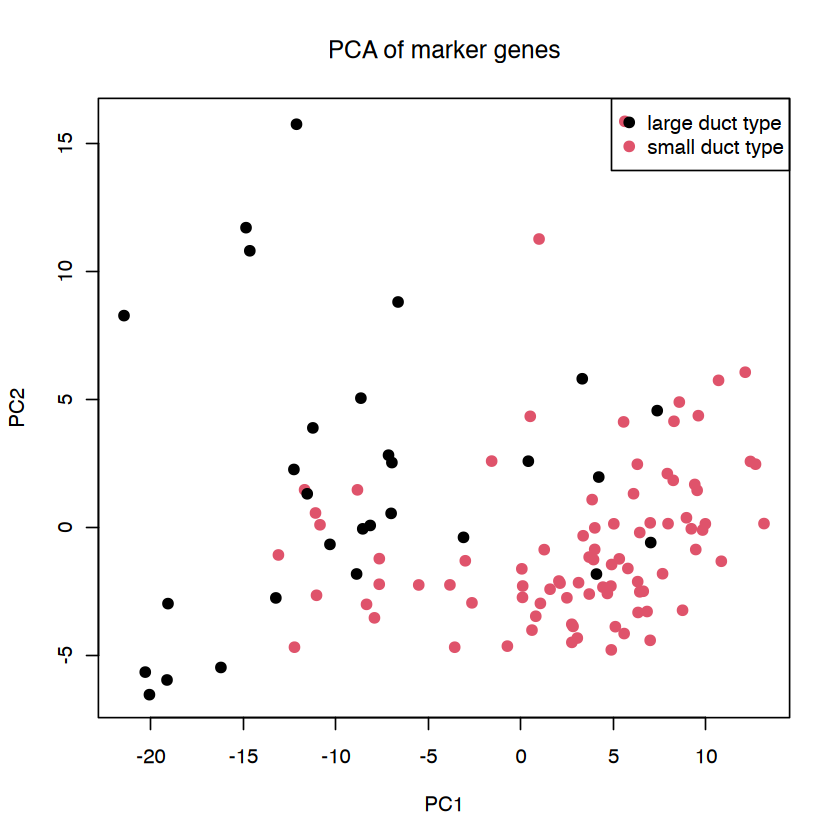

In [17]:
# PCA
expr_markers <- t(expr_labeled[marker_genes, ])
res_pca <- prcomp(expr_markers, scale. = TRUE)
plot(res_pca$x[,1:2], col=labels, pch=19, main="PCA of marker genes")
legend("topright", legend=levels(labels), col=1:2, pch=19)

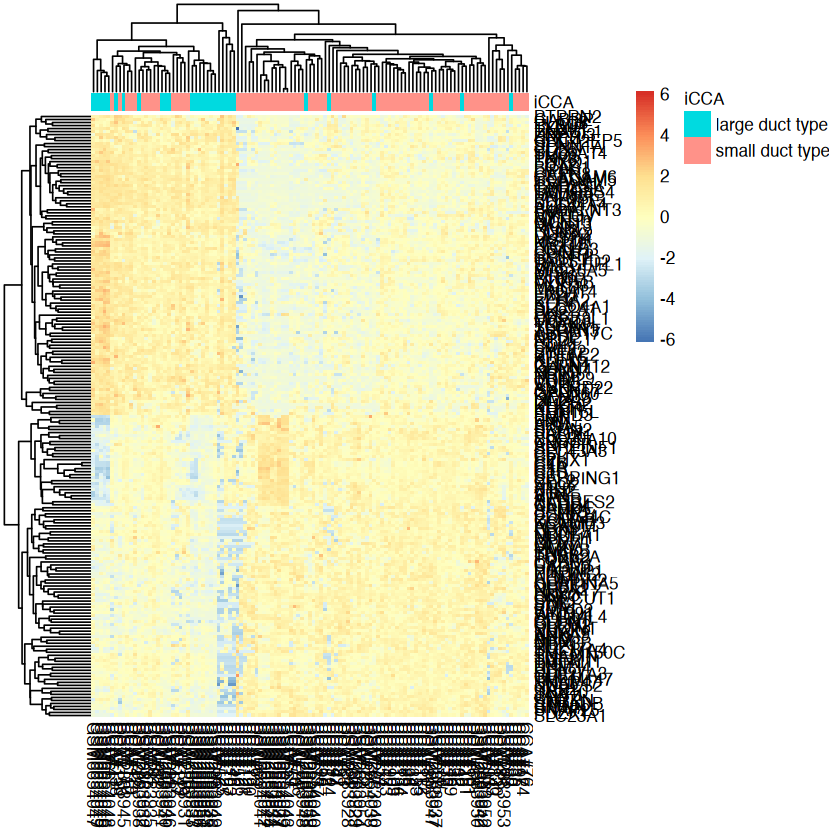

In [20]:
library(pheatmap)
mat_heat <- expr_labeled[marker_genes, ]
annotation_col <- data.frame(iCCA = labels)
rownames(annotation_col) <- colnames(mat_heat) # 保证一致
ann_colors = list(
iCCA = c("large duct type"="#E41A1C", "small duct type"="#377EB8")
)

#取当前顺序
group_order <- order(annotation_col$iCCA)
mat_heat_ordered <- mat_heat[, group_order]
annotation_col_ordered <- annotation_col[group_order, , drop=FALSE]

pheatmap(mat_heat_ordered, annotation_col=annotation_col_ordered, scale="row")

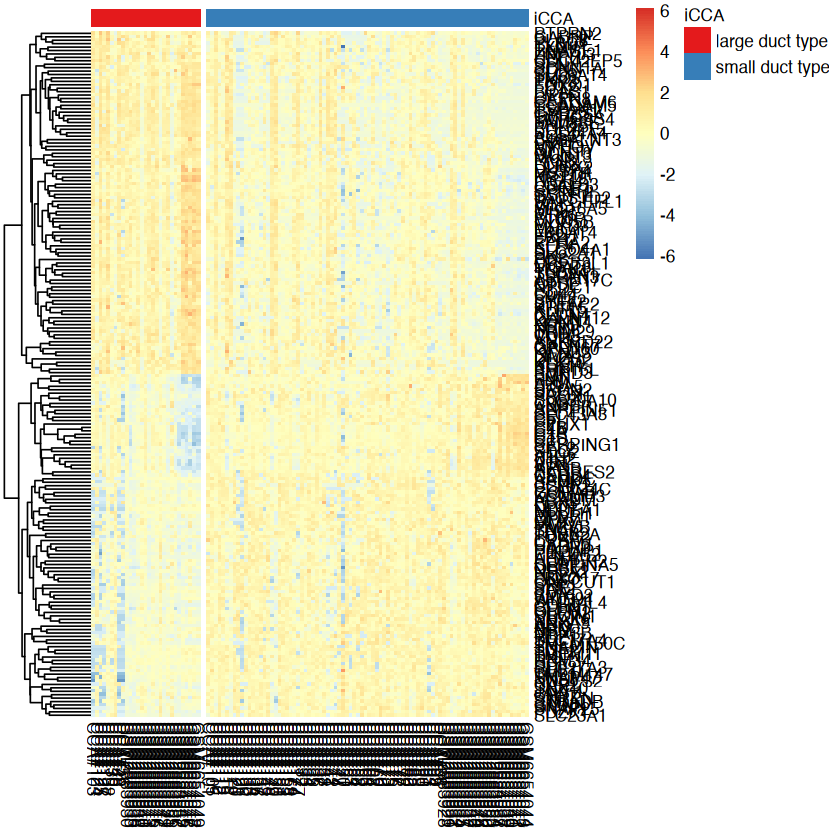

In [21]:
gap_idx <- sum(annotation_col_ordered$iCCA == "large duct type")

pheatmap(
  mat_heat_ordered,
  annotation_col = annotation_col_ordered,
  annotation_colors = ann_colors,
  scale = "row",
  cluster_cols = FALSE,
  gaps_col = gap_idx
)

## LASSO回归分类器

Best lambda: 0.02601504 


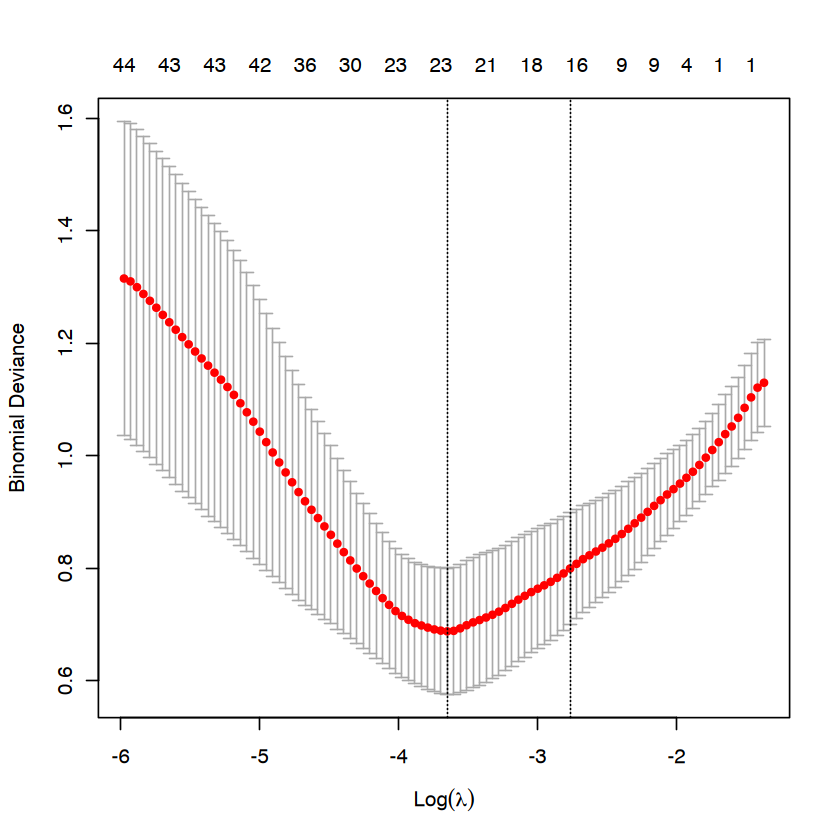

In [22]:
library(glmnet)
set.seed(123)

# 只用有标签样本
x <- t(expr_labeled[marker_genes, ])   # 行：样本，列：基因
y <- as.factor(labels)                 # large duct type / small duct type

# LASSO回归 + 5折交叉验证
cvfit <- cv.glmnet(x, y, family = "binomial", alpha = 1, nfolds = 5)

plot(cvfit)
cat("Best lambda:", cvfit$lambda.min, "\n")

In [23]:
# 预测标签
pred_label <- predict(cvfit, newx = x,  s = "lambda.min", type = "class")
# 预测概率（适用于画ROC/PR曲线）
pred_prob <- predict(cvfit, newx = x,  s = "lambda.min", type = "response")

In [24]:
table(True = y, Pred = pred_label)

                 Pred
True              large duct type small duct type
  large duct type              24               5
  small duct type               1              85

In [25]:
# 评估性能（F1-score、Precision、Recall）
# 确保两者都是因子且levels一致
pred_label <- factor(pred_label, levels = levels(y))
y <- factor(y, levels = levels(y))

library(caret)
conf_mtx <- confusionMatrix(pred_label, y, positive = "large duct type")
conf_mtx

Confusion Matrix and Statistics

                 Reference
Prediction        large duct type small duct type
  large duct type              24               1
  small duct type               5              85
                                          
               Accuracy : 0.9478          
                 95% CI : (0.8899, 0.9806)
    No Information Rate : 0.7478          
    P-Value [Acc > NIR] : 1.506e-08       
                                          
                  Kappa : 0.855           
                                          
 Mcnemar's Test P-Value : 0.2207          
                                          
            Sensitivity : 0.8276          
            Specificity : 0.9884          
         Pos Pred Value : 0.9600          
         Neg Pred Value : 0.9444          
             Prevalence : 0.2522          
         Detection Rate : 0.2087          
   Detection Prevalence : 0.2174          
      Balanced Accuracy : 0.9080          
                

In [26]:
# 查看F1、Precision、Recall
precision <- conf_mtx$byClass["Precision"]
recall <- conf_mtx$byClass["Recall"]
f1 <- conf_mtx$byClass["F1"]
print(c(Precision=precision, Recall=recall, F1=f1))

Precision.Precision       Recall.Recall               F1.F1 
          0.9600000           0.8275862           0.8888889 


Loading required package: rlang




Attaching package: 'rlang'


The following objects are masked from 'package:purrr':

    %@%, flatten, flatten_chr, flatten_dbl, flatten_int, flatten_lgl,
    flatten_raw, invoke, splice


Setting levels: control = 0, case = 1

Setting direction: controls > cases



Area under the curve: 0.9836

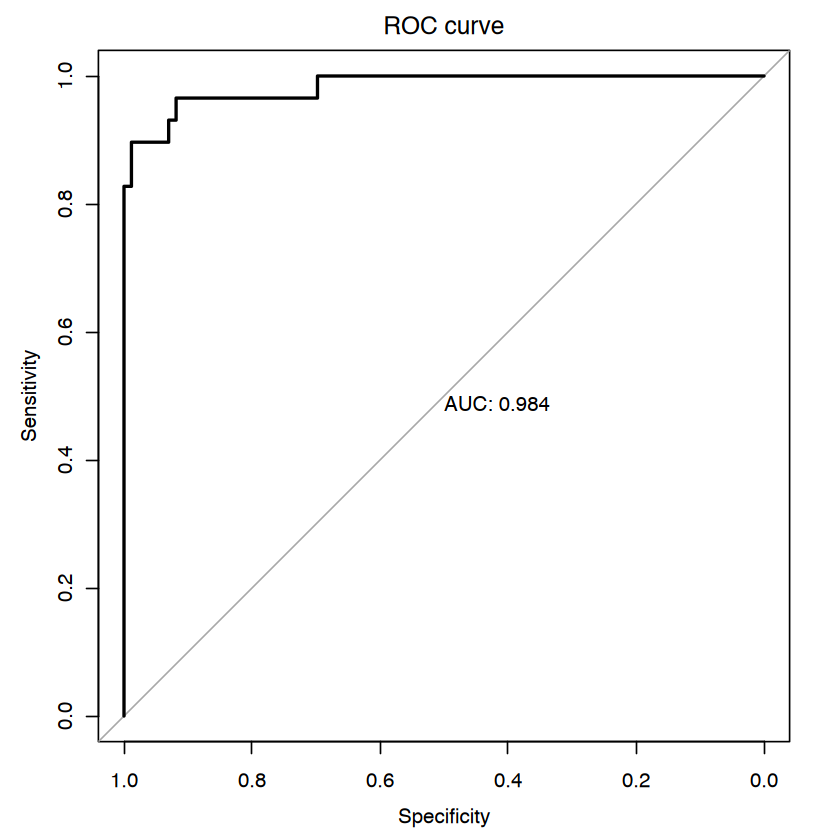

[1] 0.1385074

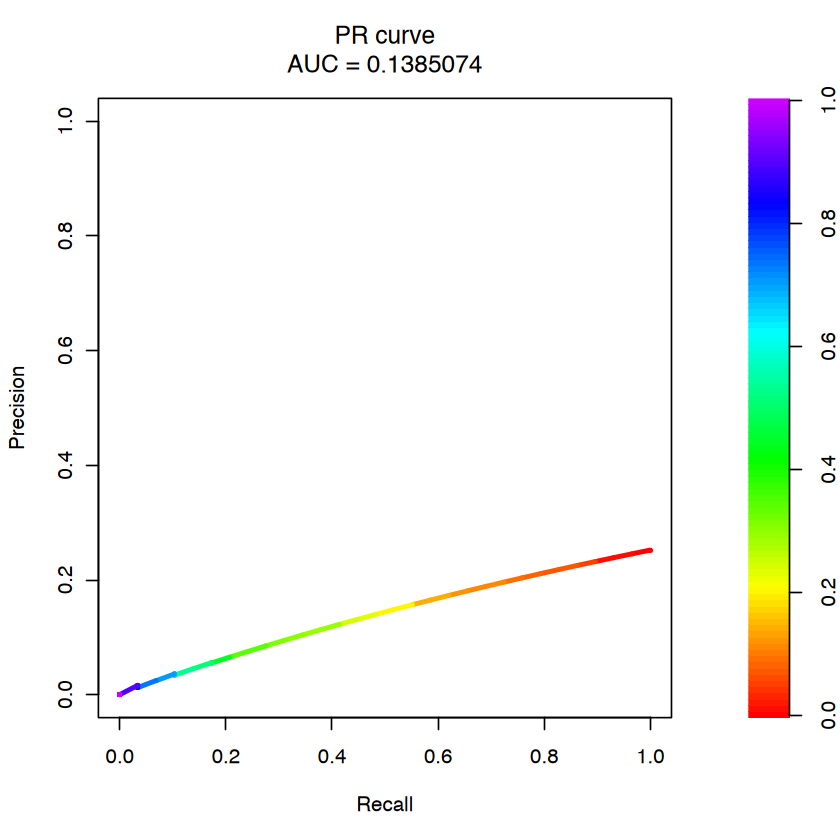

In [27]:
library(pROC)
library(PRROC)

# 注意：y要转为0/1
y01 <- ifelse(y == "large duct type", 1, 0)

# ROC
rocobj <- roc(y01, as.numeric(pred_prob))
plot(rocobj, print.auc=TRUE, main="ROC curve")
auc(rocobj)

# PR曲线（推荐！）
pr <- pr.curve(scores.class0 = pred_prob[y01==1], scores.class1 = pred_prob[y01==0], curve=TRUE)
plot(pr)
pr$auc.integral # AUC-PR数值

In [28]:
data.frame(
  Accuracy = sum(pred_label == y) / length(y),
  Precision = precision,
  Recall = recall,
  F1 = f1,
  AUC_ROC = as.numeric(auc(rocobj)),
  AUC_PR = pr$auc.integral
)

,Accuracy,Precision,Recall,F1,AUC_ROC,AUC_PR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Precision,0.9478261,0.96,0.8275862,0.8888889,0.9835605,0.1385074


In [29]:
# 用全体样本表达矩阵（marker基因子集），缺失基因需补齐
expr_all_markers <- corrected_expr_limma[marker_genes, ]   # 行：基因，列：所有样本

# 如果marker_genes有不在表达矩阵的基因，建议先筛除
marker_genes_valid <- marker_genes[marker_genes %in% rownames(corrected_expr_limma)]
expr_all_markers <- corrected_expr_limma[marker_genes_valid, ]

# 预测所有样本
pred_all <- predict(cvfit, newx = t(expr_all_markers), s = "lambda.min", type = "class")

# 赋予到sample_cluster
sample_cluster$lasso_pred <- NA
sample_cluster$lasso_pred[match(colnames(expr_all_markers), sample_cluster$Sample)] <- pred_all

# 看看预测分布
table(sample_cluster$lasso_pred, useNA = "ifany")


large duct type small duct type 
             91             495 

In [30]:
write.csv(sample_cluster, file=paste0(data_dir,"/pred.csv"))

### clinical features

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


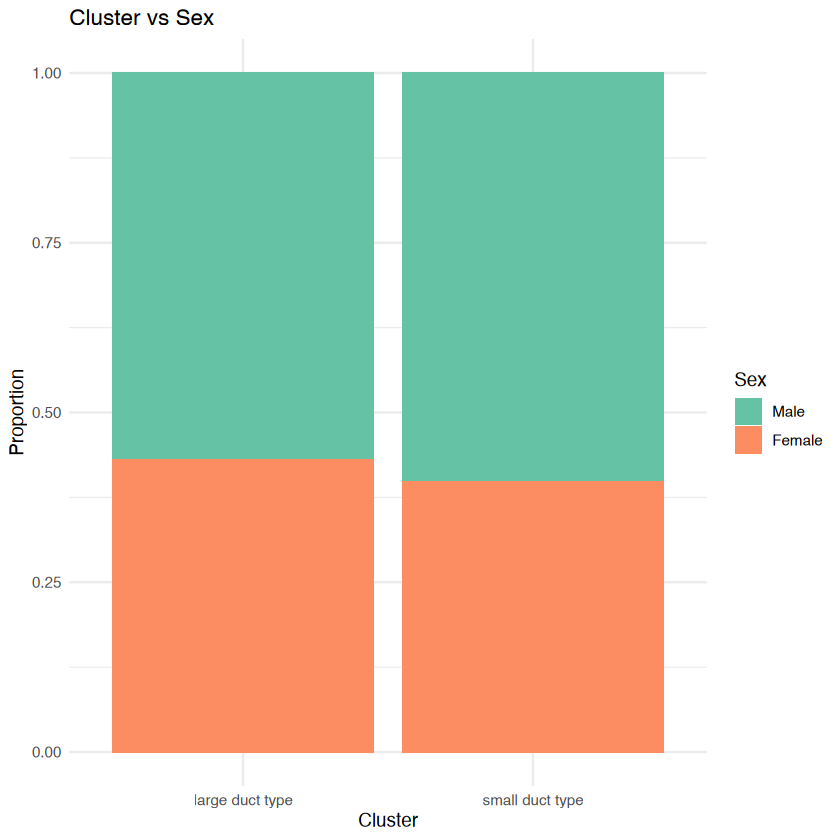

In [33]:
##分型与性别
# 性别变量标准化（有些数据Male/Female大小写不统一
sub <- sample_cluster[sample_cluster$Sex != "NA",]
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))
sub$Sex <- factor(sub$Sex, levels = c("Male", "Female"))

# 计算分型-性别比例
df_gender <- sub %>%
  group_by(lasso_pred, Sex) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

# 分型-性别堆叠条形图
ggplot(df_gender, aes(x = lasso_pred, y = percent, fill = Sex)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Sex") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


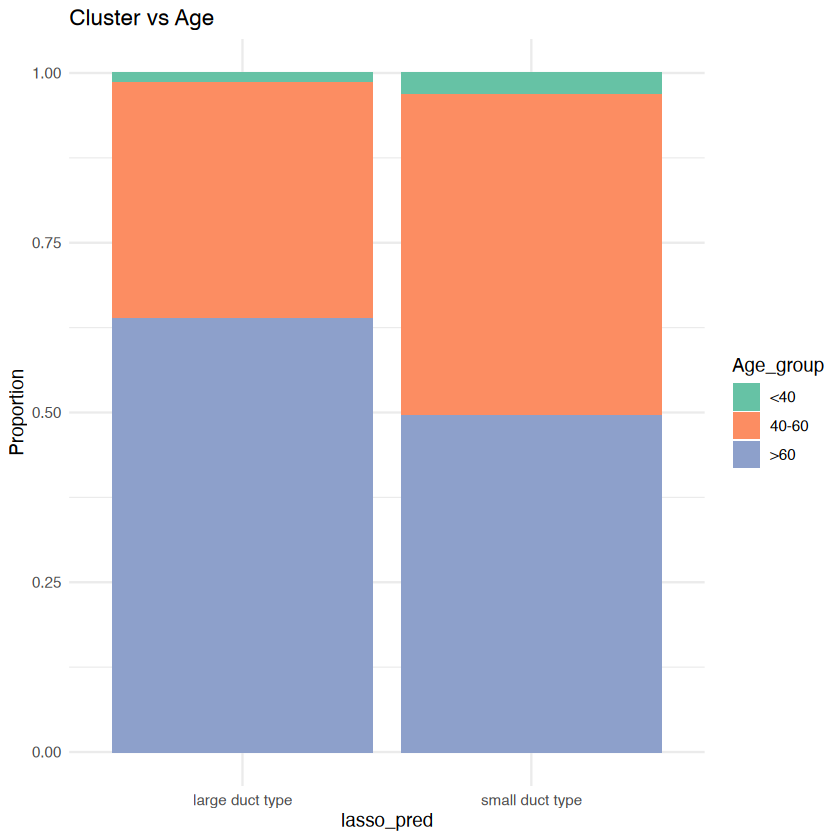

In [34]:
## 分型与Age
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Age_group != "NA",]
sub$Age_group <- factor(sub$Age_group, levels = c("<40", "40-60", ">60"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_bar <- sub %>%
  group_by(lasso_pred, Age_group) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = lasso_pred, y = Percent, fill = Age_group)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Age") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

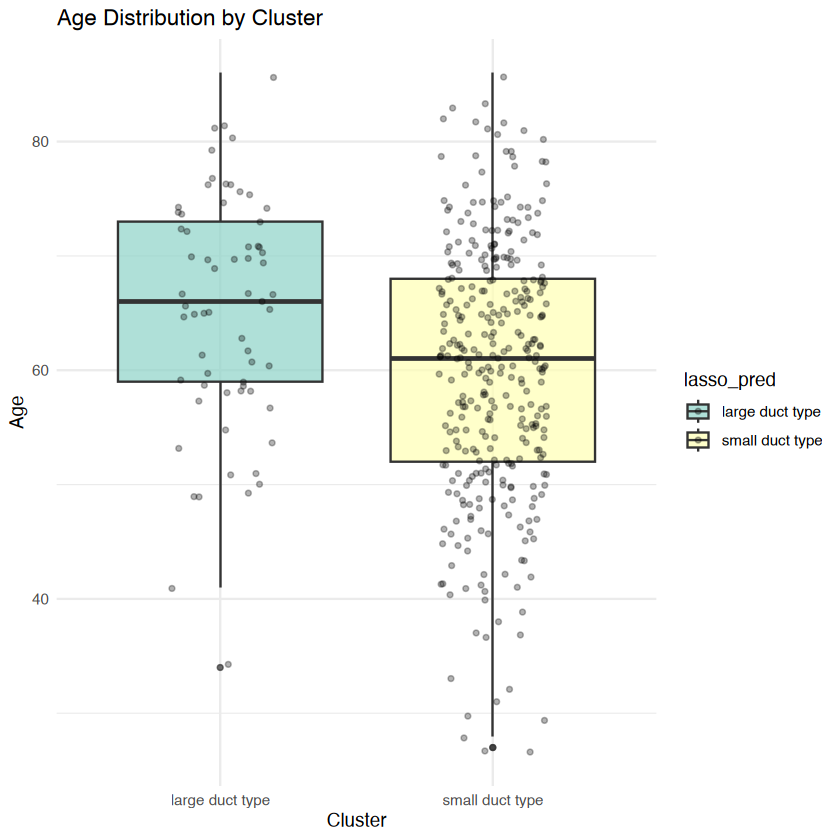

In [35]:
# 年龄转为数值型
sub <- sample_cluster[sample_cluster$Age_num != "NA",]
sub$Age_num <- as.numeric(sub$Age_num)
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

ggplot(sub, aes(x = lasso_pred, y = Age_num, fill = lasso_pred)) +
  geom_boxplot(alpha = 0.7, outlier.size=1) +
  geom_jitter(width=0.2, alpha=0.3, size=1) +
  labs(title = "Age Distribution by Cluster", x = "Cluster", y = "Age") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set3")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


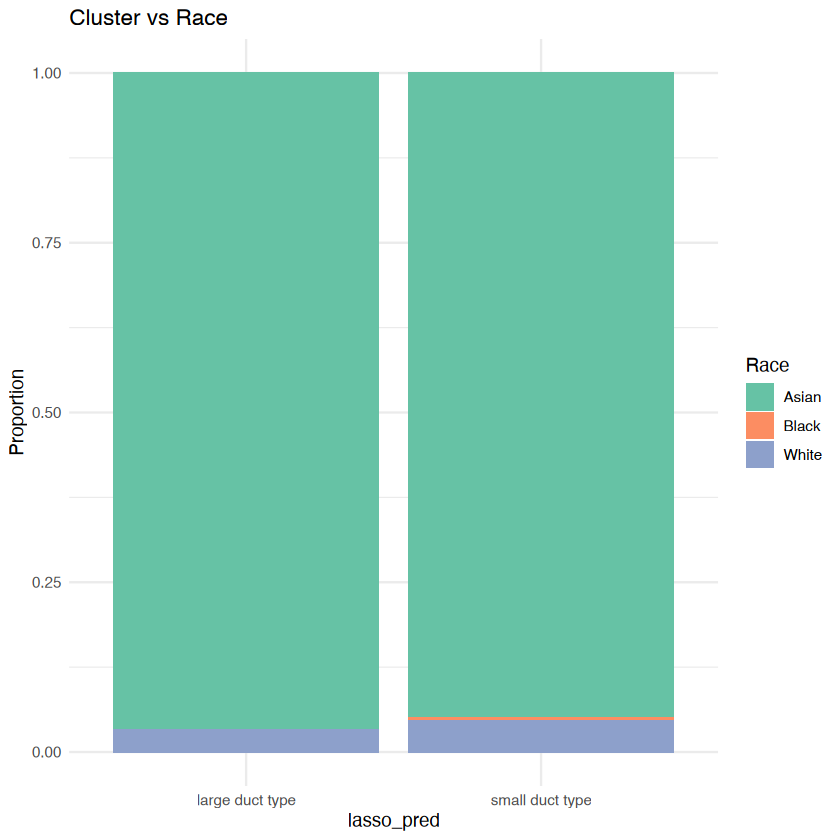

In [36]:
## 分型与race
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Race != "NA",]
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))
df_bar <- sub %>%
  group_by(lasso_pred, Race) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = lasso_pred, y = Percent, fill = Race)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Race") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


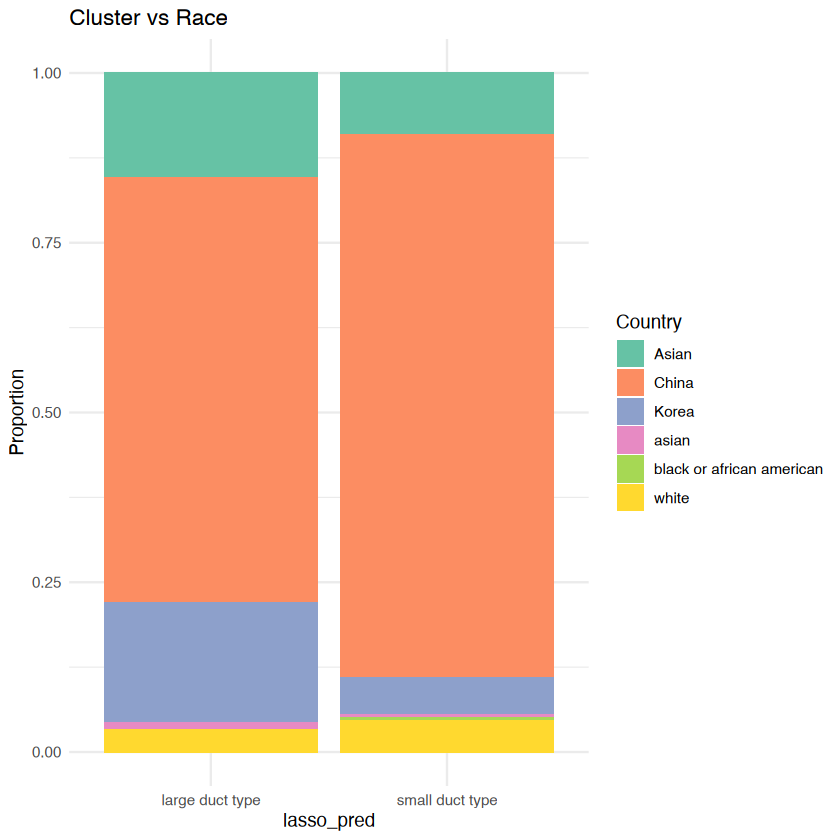

In [37]:
## 分型与Country
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Country != "NA",]
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))
df_bar <- sub %>%
  group_by(lasso_pred, Country) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = lasso_pred, y = Percent, fill = Country)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Race") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


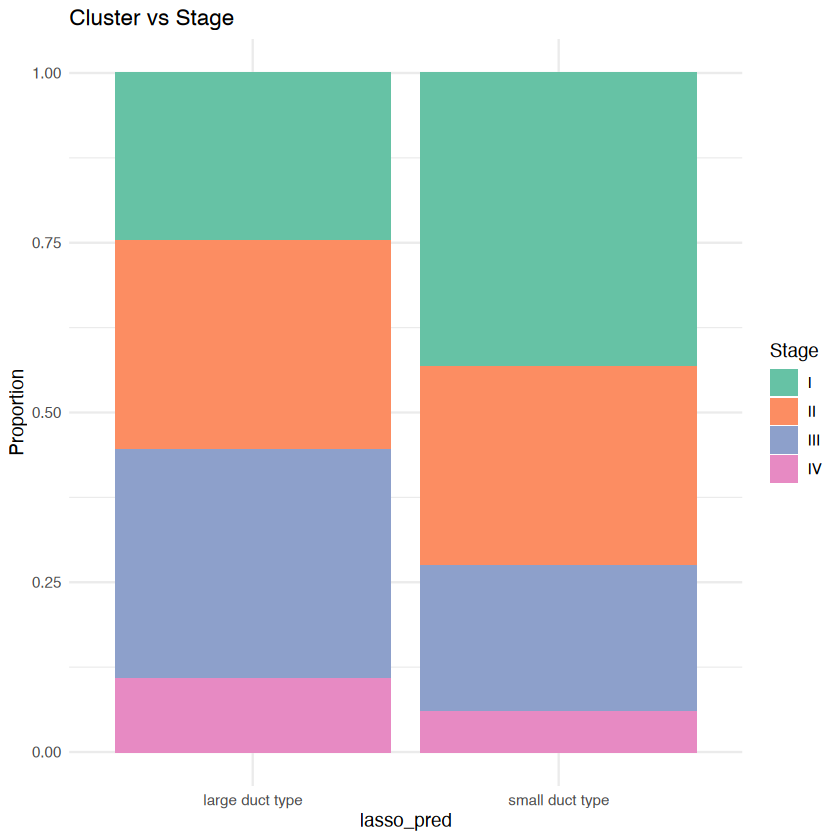

In [38]:
## 分型与Stage
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Stage != "NA",]
sub$Stage <- factor(sub$Stage, levels = c("I", "II", "III", "IV"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))
df_bar <- sub %>%
  group_by(lasso_pred, Stage) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = lasso_pred, y = Percent, fill = Stage)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Stage") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


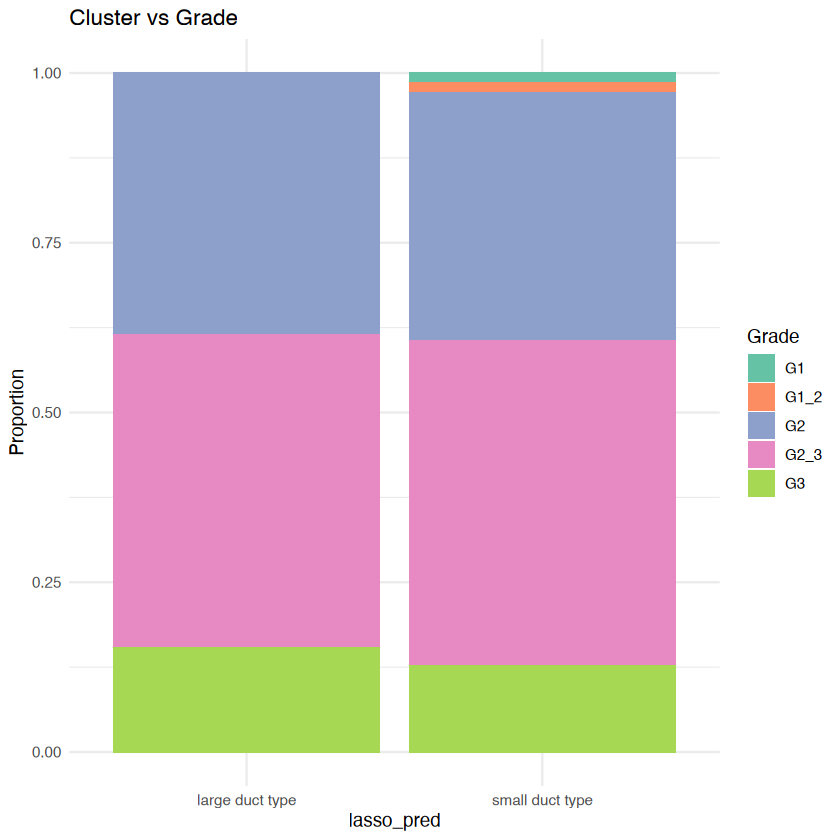

In [39]:
## 分型与Grade
# 以分型和性别为例
sub <- sample_cluster[sample_cluster$Grade != "NA",]
sub$Grade <- factor(sub$Grade, levels = c("G1", "G1_2", "G2", "G2_3", "G3"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_bar <- sub %>%
  group_by(lasso_pred, Grade) %>%
  summarise(Count = n()) %>%
  mutate(Percent = Count / sum(Count) * 100)

ggplot(df_bar, aes(x = lasso_pred, y = Percent, fill = Grade)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", title = "Cluster vs Grade") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set2")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


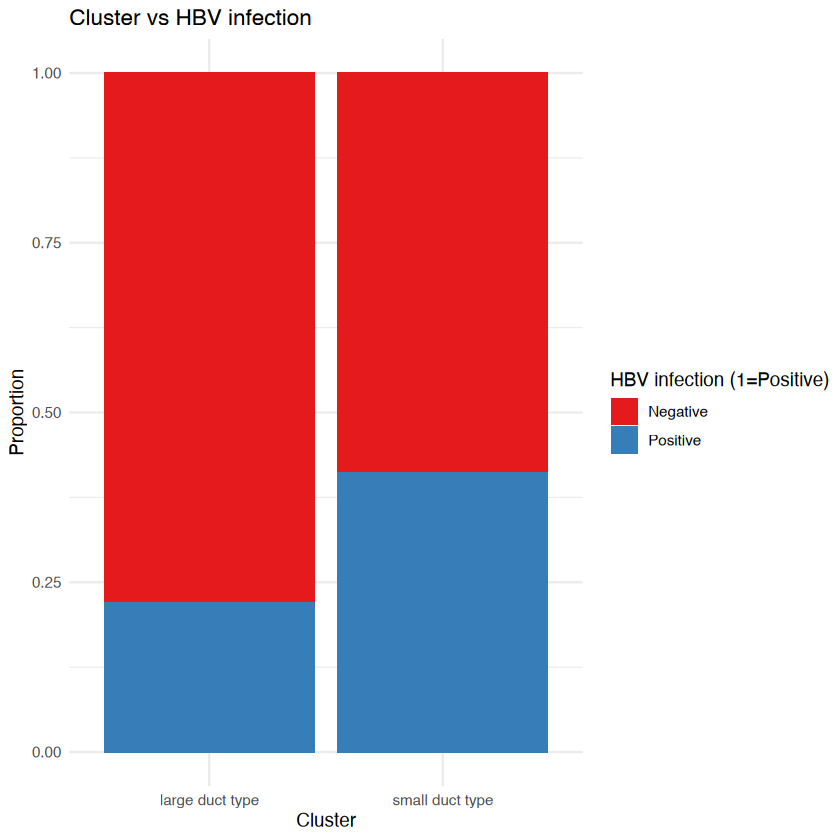

In [40]:
## 分型与HBV infection
sub <- sample_cluster[sample_cluster$`HBV infection (1=Positive)` != "NA",]
sub$`HBV infection (1=Positive)` <- factor(sub$`HBV infection (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_survival <- sub %>%
  group_by(lasso_pred, `HBV infection (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = lasso_pred, y = percent, fill = `HBV infection (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs HBV infection") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


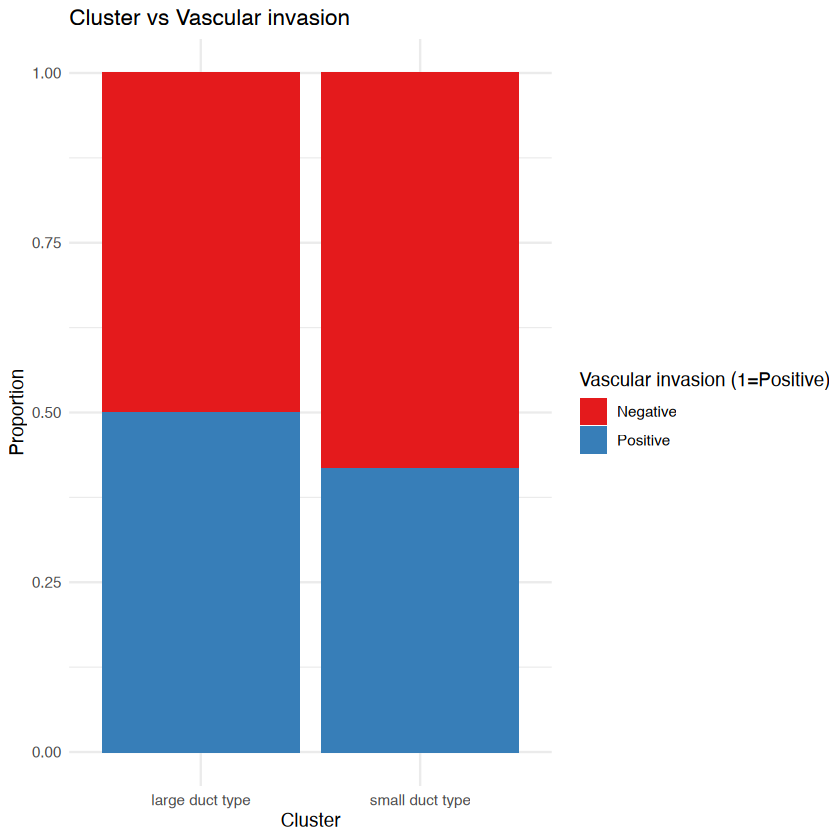

In [41]:
## 分型与Vascular invasion
sub <- sample_cluster[sample_cluster$`Vascular invasion (1=Positive)` != "NA",]
sub$`Vascular invasion (1=Positive)` <- factor(sub$`Vascular invasion (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_survival <- sub %>%
  group_by(lasso_pred, `Vascular invasion (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = lasso_pred, y = percent, fill = `Vascular invasion (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Vascular invasion") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


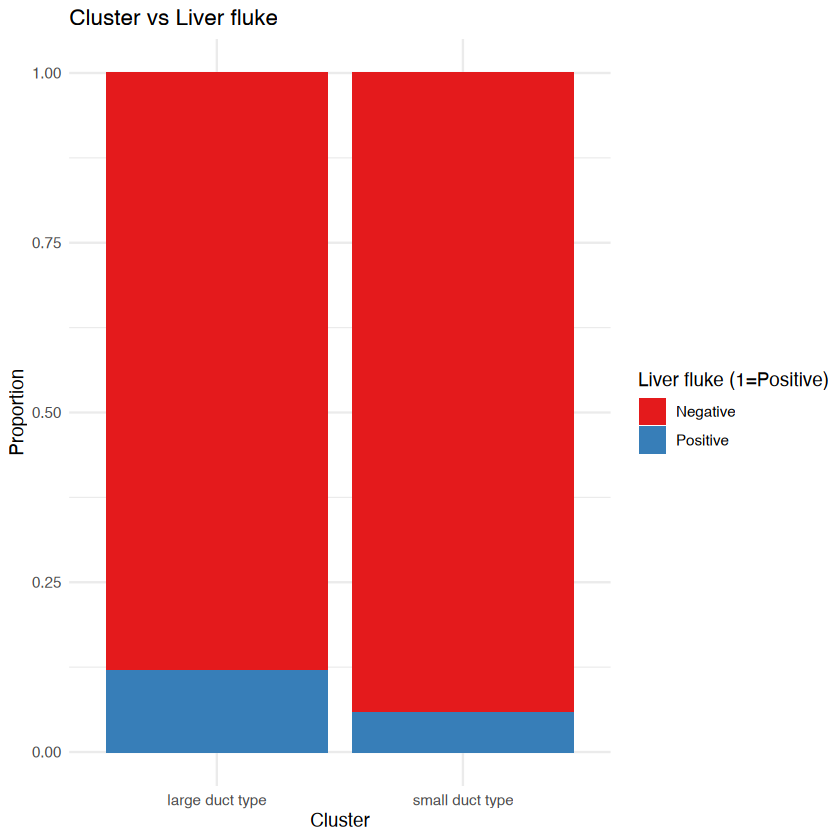

In [42]:
## 分型与Liver fluke
sub <- sample_cluster[sample_cluster$`Liver fluke (1=Positive)` != "NA",]
sub$`Liver fluke (1=Positive)` <- factor(sub$`Liver fluke (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_survival <- sub %>%
  group_by(lasso_pred, `Liver fluke (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = lasso_pred, y = percent, fill = `Liver fluke (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Liver fluke") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


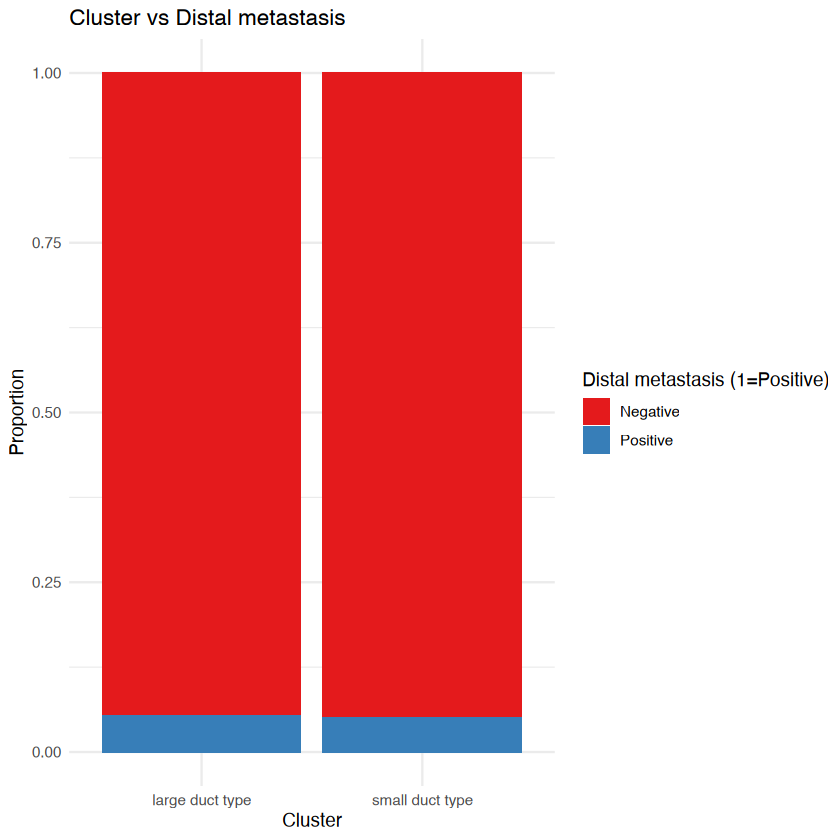

In [43]:
## 分型与Distal metastasis
sub <- sample_cluster[sample_cluster$`Distal metastasis (1=Positive)` != "NA",]
sub$`Distal metastasis (1=Positive)` <- factor(sub$`Distal metastasis (1=Positive)`, levels = c("0", "1"), labels = c("Negative", "Positive"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_survival <- sub %>%
  group_by(lasso_pred, `Distal metastasis (1=Positive)`) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = lasso_pred, y = percent, fill = `Distal metastasis (1=Positive)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Distal metastasis") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

### duct type

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


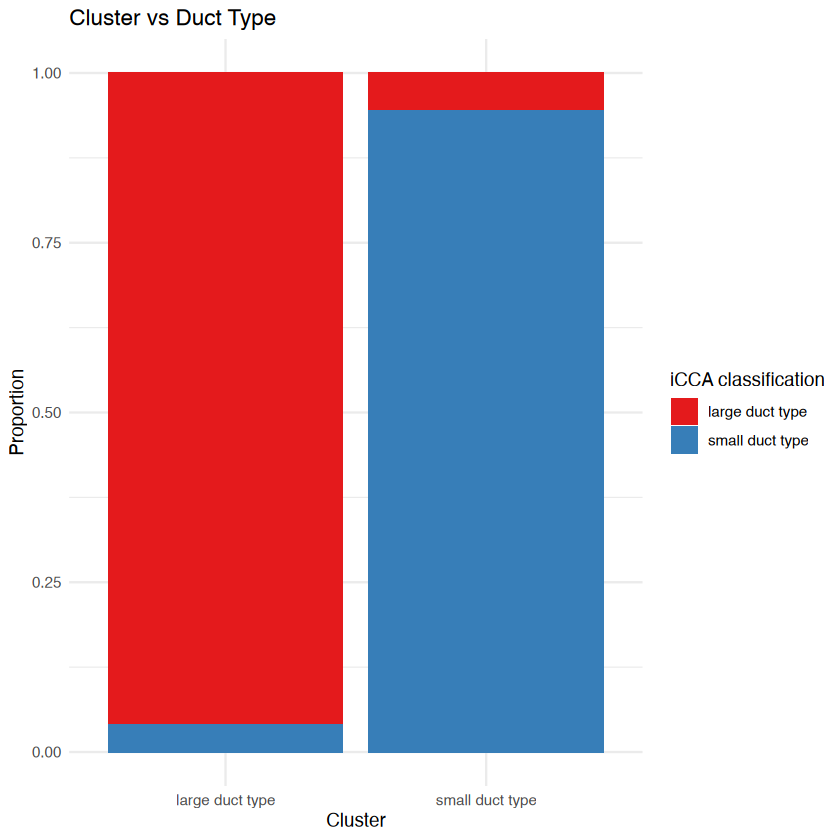

In [44]:
##分型与胆管类型
sub <- sample_cluster[sample_cluster$'iCCA classification' != "w/o",]
sub$`iCCA classification` <- factor(sub$`iCCA classification`)
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_duct <- sub %>%
  filter(!is.na(`iCCA classification`)) %>%
  group_by(lasso_pred, `iCCA classification`) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_duct, aes(x = lasso_pred, y = percent, fill = `iCCA classification`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Duct Type") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


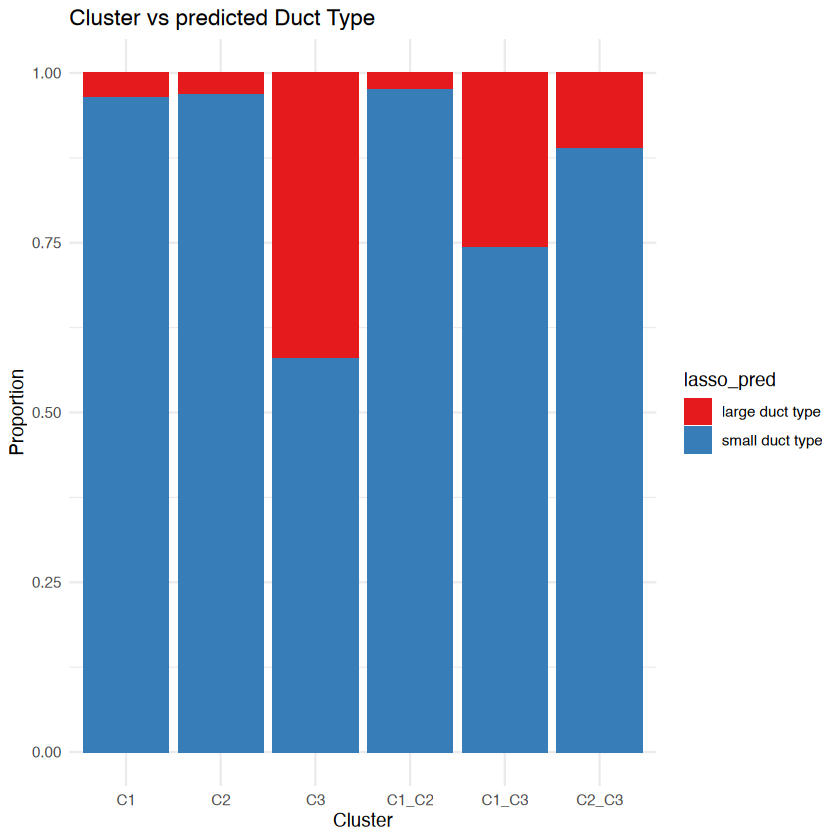

In [48]:
##分型与胆管类型
sample_cluster$lasso_pred <- factor(sample_cluster$lasso_pred, levels = c("large duct type", "small duct type"))
sample_cluster$Ensemble <- factor(sample_cluster$Ensemble, levels = c("C1","C2","C3","C1_C2","C1_C3","C2_C3"))
df_duct <- sample_cluster %>%
  group_by(lasso_pred, Ensemble) %>%
  summarise(n = n()) %>%
  group_by(Ensemble) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_duct, aes(x = Ensemble, y = percent, fill = lasso_pred)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs predicted Duct Type") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


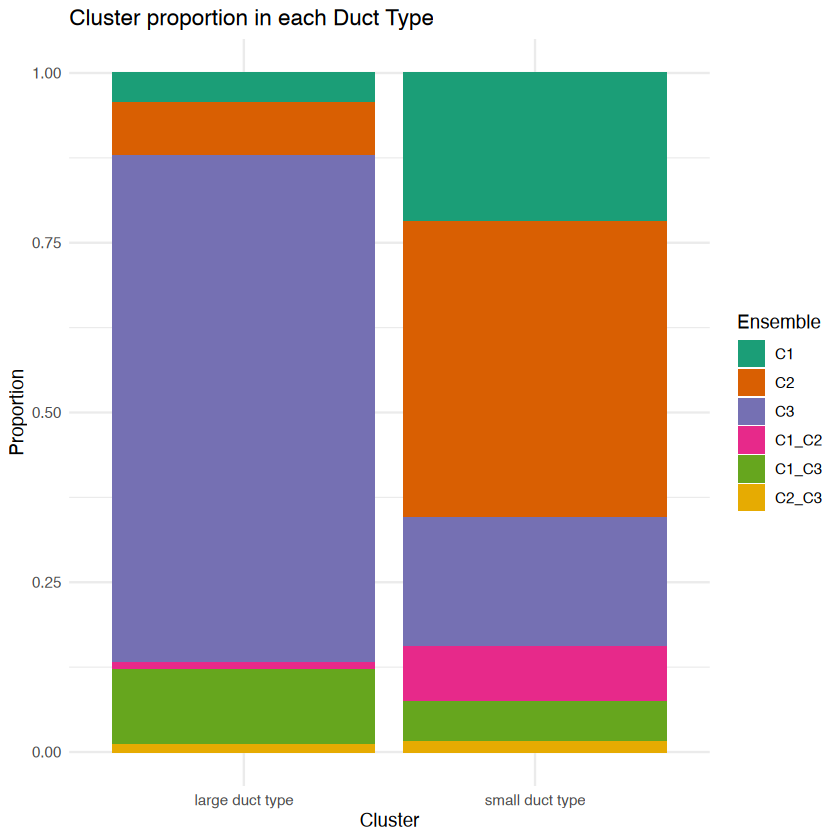

In [50]:
df_cluster <- sample_cluster %>%
  group_by(lasso_pred, Ensemble) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)
df_cluster$lasso_pred<- factor(df_cluster$lasso_pred, levels = c("large duct type", "small duct type"))

ggplot(df_cluster, aes(x = lasso_pred, y = percent, fill = Ensemble)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster proportion in each Duct Type") +
  theme_minimal() +
  scale_fill_brewer(palette = "Dark2")

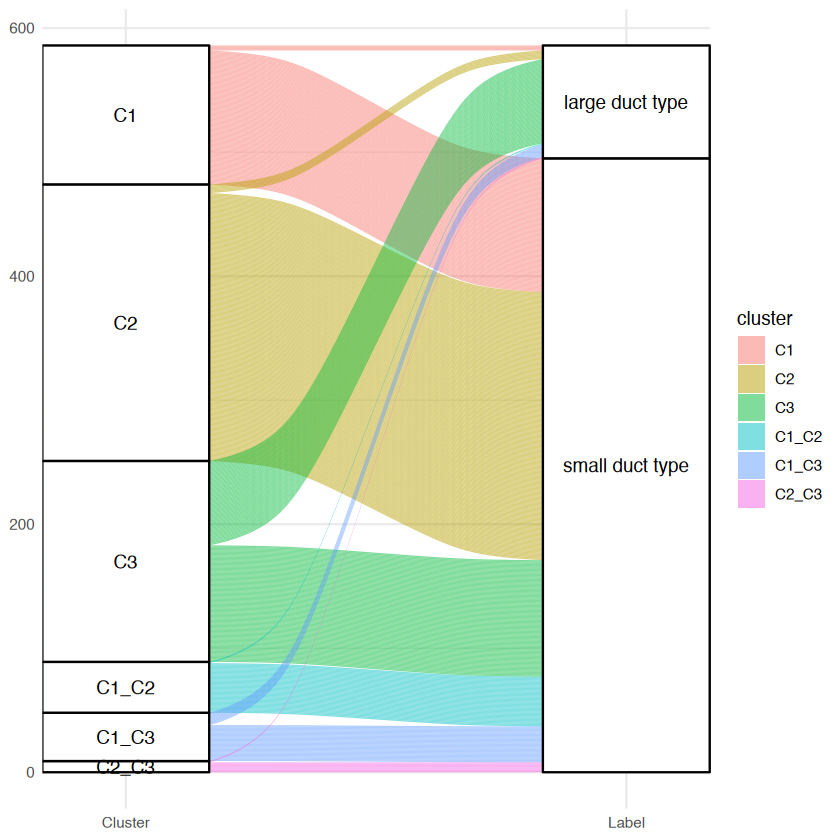

In [49]:
library(ggalluvial)
data <- data.frame(
  cluster = sample_cluster$Ensemble,
  label = sample_cluster$lasso_pred
)
ggplot(data,
       aes(axis1 = cluster, axis2 = label)) +
  geom_alluvium(aes(fill = cluster)) +
  geom_stratum() +
  geom_text(stat = "stratum", aes(label = after_stat(stratum))) +
  scale_x_discrete(limits = c("Cluster", "Label"), expand = c(.05, .05)) +
  theme_minimal()

### survival

`summarise()` has grouped output by 'lasso_pred'. You can override using the
`.groups` argument.


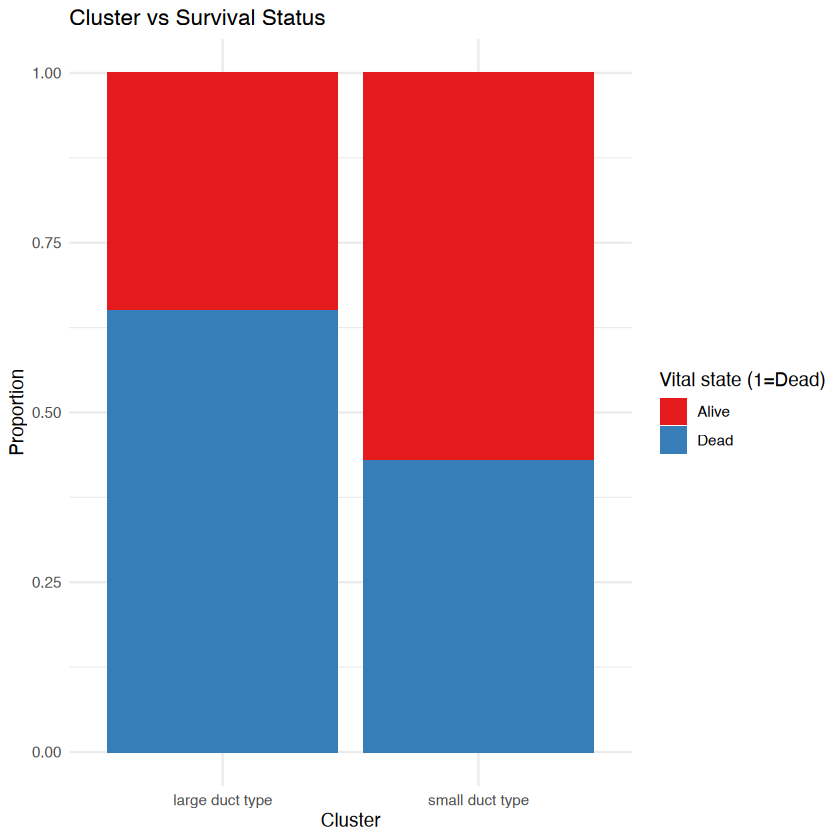

In [51]:
## 分型与survival state
sub <- sample_cluster[sample_cluster$`Vital state (1=Dead)` != "NA",]
sub$`Vital state (1=Dead)` <- factor(sub$`Vital state (1=Dead)`, levels = c("0", "1"), labels = c("Alive", "Dead"))
sub$lasso_pred <- factor(sub$lasso_pred, levels = c("large duct type", "small duct type"))

df_survival <- sub %>%
  group_by(lasso_pred, `Vital state (1=Dead)`) %>%
  summarise(n = n()) %>%
  group_by(lasso_pred) %>%
  mutate(percent = n / sum(n) * 100)

ggplot(df_survival, aes(x = lasso_pred, y = percent, fill = `Vital state (1=Dead)`)) +
  geom_bar(stat = "identity", position = "fill") +
  labs(y = "Proportion", x = "Cluster", title = "Cluster vs Survival Status") +
  theme_minimal() +
  scale_fill_brewer(palette = "Set1")

In [52]:
## 分型与survival
library(survival)
library(survminer)
library(dplyr)

# 1. 整理数据
km_data <- sample_cluster %>%
  filter(`Vital state (1=Dead)` != "NA") %>%
  select(`Overall survival (months)`, `Vital state (1=Dead)`, lasso_pred) %>%
  mutate(
    # 转为数值型
    OS_months = as.numeric(`Overall survival (months)`),
    Status = as.numeric(`Vital state (1=Dead)`),  # 1=Dead, 0=Alive
    Cluster = lasso_pred
  )
km_data <- km_data %>%
  filter(OS_months >=1)


Attaching package: 'survival'


The following object is masked from 'package:caret':

    cluster


Loading required package: ggpubr


Attaching package: 'survminer'


The following object is masked from 'package:survival':

    myeloma




In [53]:
# Surv(生存时间, 状态)  状态1=事件（死亡）, 0=截尾（活）
surv_object <- Surv(time = km_data$OS_months, event = km_data$Status)

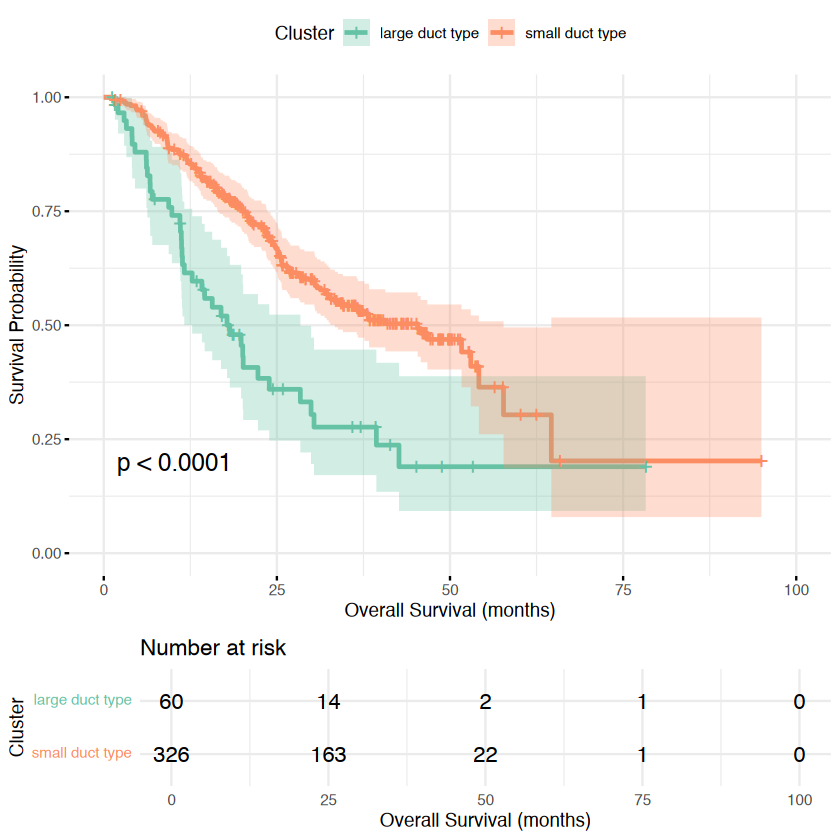

In [54]:
# 拟合KM曲线
fit <- survfit(surv_object ~ Cluster, data = km_data)

# 绘制KM曲线
ggsurvplot(
  fit, 
  data = km_data,
  pval = TRUE,                 # 显示log-rank检验p值
  risk.table = TRUE,           # 显示风险表
  conf.int = TRUE,             # 置信区间
  legend.title = "Cluster",
  legend.labs = levels(factor(km_data$Cluster)), # 保证图例顺序
  palette = "Set2",            # 你也可以自定义颜色
  xlab = "Overall Survival (months)",
  ylab = "Survival Probability",
  #xlim = c(0, 60),
  ggtheme = theme_minimal()
)